In [16]:
import sys
import os
sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.subsampling import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.linear_model import CoxnetSurvivalAnalysis, CoxPHSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [17]:
dataset = pd.read_csv("../data/data_final.csv")

diagnosis_variables = []

with open("../data/diagnosis_final.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../data/treatment_final.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

In [18]:
# Find duplicated patients with regional ln recurrence = 1
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False)) #& (survival_dataset['Regional LN recurrence'] == 1)

# For each duplicated PERSON_ID with recurrence, keep only the row with the lowest survival days
to_remove = (
    survival_dataset[mask]
    .sort_values(['PERSON_ID', 'Survival days'], ascending=[True, True])
    .groupby('PERSON_ID')
    .head(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

In [19]:
# Prepare data
data_x = survival_dataset[feature_columns]

data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
# Since every duplicated patient has a consistent event indicator (regional ln recurrence) I can use this method
groups = survival_dataset['PERSON_ID']

In [20]:
# first fold becomes the held-out test set
sgkf_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=12)

# Get first fold as test set
first_split = list(sgkf_outer.split(X=data_x, y=survival_dataset['Regional LN recurrence']))[0]
train_pool_index, test_index = first_split

# Test set - held out for final evaluation
x_test = data_x.iloc[test_index]
y_test = data_y[test_index]
test_dataset = survival_dataset.iloc[test_index].copy()

# Training pool - will be used for 4-fold CV recalibration evaluation
x_train_pool = data_x.iloc[train_pool_index]
y_train_pool = data_y[train_pool_index]
train_pool_dataset = survival_dataset.iloc[train_pool_index].copy()

print("="*70)
print("DATA SPLIT")
print("="*70)
print(f"Test set (held out): {len(x_test)} samples, {y_test['event'].sum()} events")
print(f"Training pool (for 4-fold CV): {len(x_train_pool)} samples, {y_train_pool['event'].sum()} events")

DATA SPLIT
Test set (held out): 594 samples, 6 events
Training pool (for 4-fold CV): 2376 samples, 27 events


In [21]:
# Load results from repeated_full (normal) and repeated_sub (subsampling) folders
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for publication-quality figures
sns.set_style("whitegrid")
sns.set_context("poster", font_scale=1.2)

# Load repeated CV results - Full cohort (no subsampling)
cox_full = pd.read_csv('../results/repeated_full/cox_full_cleaned.csv')
gbm_full = pd.read_csv('../results/repeated_full/gbm_full.csv')
rsf_full = pd.read_csv('../results/repeated_full/rsf_full.csv')
ssvm_full = pd.read_csv('../results/repeated_full/ssvm_full.csv')

# Load repeated CV results - Subsampling
cox_sub = pd.read_csv('../results/repeated_sub/cox_sub_cleaned.csv')
gbm_sub = pd.read_csv('../results/repeated_sub/gbm_sub.csv')
rsf_sub = pd.read_csv('../results/repeated_sub/rsf_sub.csv')
ssvm_sub = pd.read_csv('../results/repeated_sub/ssvm_sub.csv')

In [22]:
# best hyperparams per model, pulled from subsampling results
from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score, accuracy_score
from sklearn.metrics import roc_curve
from sksurv.ensemble import GradientBoostingSurvivalAnalysis, RandomSurvivalForest
from sksurv.svm import FastSurvivalSVM

print("="*70)
print("BEST HYPERPARAMETERS FOR EACH MODEL (from subsampling results)")
print("="*70)

# Cox best params (row 4 as identified in results.ipynb)
cox_best = cox_sub.iloc[4]
print("\nCox Model (Elastic Net):")
print(f"  n_controls: {int(cox_best['n_controls'])}")
print(f"  l1_ratio: {cox_best['l1_ratio']}")
print(f"  alpha: {cox_best['alpha']}")
print(f"  c-index-ipcw_mean: {cox_best['c-index-ipcw_mean']:.4f}")

# GBM best params (row 0)
gbm_best = gbm_sub.iloc[0]
print("\nGBM (Gradient Boosting Survival):")
print(f"  n_controls_per_case: {int(gbm_best['n_controls_per_case'])}")
print(f"  learning_rate: {gbm_best['learning_rate']}")
print(f"  n_estimators: {int(gbm_best['n_estimators'])}")
print(f"  max_depth: {int(gbm_best['max_depth'])}")
print(f"  min_samples_split: {int(gbm_best['min_samples_split'])}")
print(f"  c-index-ipcw_mean: {gbm_best['c-index-ipcw_mean']:.4f}")

# RSF best params (row 1)
rsf_best = rsf_sub.iloc[1]
print("\nRSF (Random Survival Forest):")
print(f"  n_controls_per_case: {int(rsf_best['n_controls_per_case'])}")
print(f"  n_estimators: {int(rsf_best['n_estimators'])}")
max_depth_rsf = None if pd.isna(rsf_best['max_depth']) else int(rsf_best['max_depth'])
print(f"  max_depth: {max_depth_rsf}")
print(f"  max_features: {rsf_best['max_features']}")
print(f"  min_samples_leaf: {int(rsf_best['min_samples_leaf'])}")
print(f"  c-index-ipcw_mean: {rsf_best['c-index-ipcw_mean']:.4f}")

# SSVM best params (row 0)
ssvm_best = ssvm_sub.iloc[0]
print("\nSSVM (Survival SVM):")
print(f"  n_controls_per_case: {int(ssvm_best['n_controls_per_case'])}")
print(f"  alpha: {ssvm_best['alpha']}")
print(f"  c-index-ipcw_mean: {ssvm_best['c-index-ipcw_mean']:.4f}")

# Prepare RSF max_features
max_features_rsf = rsf_best['max_features']
if isinstance(max_features_rsf, str):
    try:
        max_features_rsf = float(max_features_rsf)
    except ValueError:
        pass  # Keep as string (e.g., 'sqrt', 'log2')

BEST HYPERPARAMETERS FOR EACH MODEL (from subsampling results)

Cox Model (Elastic Net):
  n_controls: 1
  l1_ratio: 0.5
  alpha: 0.1
  c-index-ipcw_mean: 0.7564

GBM (Gradient Boosting Survival):
  n_controls_per_case: 15
  learning_rate: 0.1
  n_estimators: 500
  max_depth: 2
  min_samples_split: 10
  c-index-ipcw_mean: 0.7785

RSF (Random Survival Forest):
  n_controls_per_case: 1
  n_estimators: 100
  max_depth: 10
  max_features: sqrt
  min_samples_leaf: 3
  c-index-ipcw_mean: 0.7611

SSVM (Survival SVM):
  n_controls_per_case: 1
  alpha: 0.01
  c-index-ipcw_mean: 0.7292


In [23]:
# repeated 4-fold CV for classification metrics (AUC, accuracy) at 4 time horizons + cumulative

from scipy.stats import wilcoxon
from scipy.stats import levene

# Time horizons for evaluation
time_points = [650, 1100, 1600, 1825]  # days

# Number of repetitions and folds
n_repetitions = 5
n_folds = 4
total_experiments = n_repetitions * n_folds

print("="*70)
print("REPEATED 4-FOLD CV: AUC & ACCURACY AT MULTIPLE TIME POINTS")
print("="*70)
print(f"Time points: {time_points} days")
print(f"Repetitions: {n_repetitions}")
print(f"Folds per repetition: {n_folds}")
print(f"Total experiments: {total_experiments}")

# Storage for all models' results - per time point + cumulative
all_models_results = {}
for model in ['Cox', 'GBM', 'RSF', 'SSVM']:
    all_models_results[model] = {}
    for tp in time_points:
        all_models_results[model][f'auc_{tp}'] = []
        all_models_results[model][f'accuracy_{tp}'] = []
    # Cumulative (entire time - using final observation)
    all_models_results[model]['auc_cumulative'] = []
    all_models_results[model]['accuracy_cumulative'] = []

# Detailed experiment tracking
all_experiment_details = []

for rep in range(n_repetitions):
    print(f"\n{'='*70}")
    print(f"REPETITION {rep + 1}/{n_repetitions}")
    print(f"{'='*70}")
    
    # Create CV split with different random state for each repetition
    sgkf_rep = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=12 + rep)
    
    for fold_idx, (train_index, val_index) in enumerate(sgkf_rep.split(X=x_train_pool, y=train_pool_dataset['Regional LN recurrence'])):
        experiment_num = rep * n_folds + fold_idx + 1
        print(f"\n--- Rep {rep+1}, Fold {fold_idx+1} (Exp {experiment_num}/{total_experiments}) ---")
        
        # Get train and validation data
        x_train_fold = x_train_pool.iloc[train_index]
        y_train_fold = y_train_pool[train_index]
        x_val = x_train_pool.iloc[val_index]
        y_val = y_train_pool[val_index]
        train_fold_df = train_pool_dataset.iloc[train_index].copy()
        val_fold_df = train_pool_dataset.iloc[val_index].copy()
        
        experiment_detail = {
            'repetition': rep + 1,
            'fold': fold_idx + 1,
            'experiment': experiment_num,
            'n_train': len(x_train_fold),
            'n_val': len(x_val)
        }
        
        # Cumulative binary outcome (event at any time)
        y_true_cumulative = val_fold_df['Regional LN recurrence'].values
        
        # -- Cox --
        try:
            # Subsample training data
            x_train_sub_cox, y_train_sub_cox, _ = sample_case_control(
                train_fold=train_fold_df,
                event_col='Regional LN recurrence',
                time_col='Survival days',
                n_controls_per_case=int(cox_best['n_controls']),
                feature_columns=feature_columns,
                random_state=12 + rep
            )
            
            # Scale data
            scaler_cox = StandardScaler()
            x_train_sub_scaled = scaler_cox.fit_transform(x_train_sub_cox)
            x_val_scaled = scaler_cox.transform(x_val)
            
            # Train Cox model
            cox_model = CoxnetSurvivalAnalysis(
                l1_ratio=cox_best['l1_ratio'],
                alphas=[cox_best['alpha']],
                fit_baseline_model=True
            )
            cox_model.fit(x_train_sub_scaled, y_train_sub_cox)
            
            # Get survival functions
            surv_funcs_cox = cox_model.predict_survival_function(x_val_scaled)
            
            # Evaluate at each time point
            for tp in time_points:
                y_true_binary = ((val_fold_df['Regional LN recurrence'] == 1) & 
                                 (val_fold_df['Survival days'] <= tp)).astype(int).values
                
                if y_true_binary.sum() > 0 and y_true_binary.sum() < len(y_true_binary):
                    y_pred_proba = 1 - np.array([fn(tp) for fn in surv_funcs_cox])
                    y_pred_binary = (y_pred_proba >= 0.5).astype(int)
                    
                    auc = roc_auc_score(y_true_binary, y_pred_proba)
                    accuracy = accuracy_score(y_true_binary, y_pred_binary)
                    
                    all_models_results['Cox'][f'auc_{tp}'].append(auc)
                    all_models_results['Cox'][f'accuracy_{tp}'].append(accuracy)
                    experiment_detail[f'cox_auc_{tp}'] = auc
                    experiment_detail[f'cox_accuracy_{tp}'] = accuracy
            
            # Cumulative (using risk scores for AUC)
            risk_scores_cox = cox_model.predict(x_val_scaled)
            auc_cum = roc_auc_score(y_true_cumulative, risk_scores_cox)
            y_pred_cum = (risk_scores_cox >= np.median(risk_scores_cox)).astype(int)
            accuracy_cum = accuracy_score(y_true_cumulative, y_pred_cum)
            
            all_models_results['Cox']['auc_cumulative'].append(auc_cum)
            all_models_results['Cox']['accuracy_cumulative'].append(accuracy_cum)
            experiment_detail['cox_auc_cumulative'] = auc_cum
            experiment_detail['cox_accuracy_cumulative'] = accuracy_cum
            
            print(f"  Cox:  AUC@1825={all_models_results['Cox']['auc_1825'][-1]:.4f}, AUC_cum={auc_cum:.4f}")
            
        except Exception as e:
            print(f"  Cox:  ERROR - {str(e)[:50]}")
        
        # -- GBM --
        try:
            # Subsample training data
            x_train_sub_gbm, y_train_sub_gbm, _ = sample_case_control(
                train_fold=train_fold_df,
                event_col='Regional LN recurrence',
                time_col='Survival days',
                n_controls_per_case=int(gbm_best['n_controls_per_case']),
                feature_columns=feature_columns,
                random_state=12 + rep
            )
            
            # Train GBM model (no scaling needed)
            gbm_model = GradientBoostingSurvivalAnalysis(
                learning_rate=gbm_best['learning_rate'],
                n_estimators=int(gbm_best['n_estimators']),
                max_depth=int(gbm_best['max_depth']),
                min_samples_split=int(gbm_best['min_samples_split']),
                random_state=12 + rep
            )
            gbm_model.fit(x_train_sub_gbm, y_train_sub_gbm)
            
            # Get survival functions
            surv_funcs_gbm = gbm_model.predict_survival_function(x_val)
            
            # Evaluate at each time point
            for tp in time_points:
                y_true_binary = ((val_fold_df['Regional LN recurrence'] == 1) & 
                                 (val_fold_df['Survival days'] <= tp)).astype(int).values
                
                if y_true_binary.sum() > 0 and y_true_binary.sum() < len(y_true_binary):
                    y_pred_proba = 1 - np.array([fn(tp) for fn in surv_funcs_gbm])
                    y_pred_binary = (y_pred_proba >= 0.5).astype(int)
                    
                    auc = roc_auc_score(y_true_binary, y_pred_proba)
                    accuracy = accuracy_score(y_true_binary, y_pred_binary)
                    
                    all_models_results['GBM'][f'auc_{tp}'].append(auc)
                    all_models_results['GBM'][f'accuracy_{tp}'].append(accuracy)
                    experiment_detail[f'gbm_auc_{tp}'] = auc
                    experiment_detail[f'gbm_accuracy_{tp}'] = accuracy
            
            # Cumulative
            risk_scores_gbm = gbm_model.predict(x_val)
            auc_cum = roc_auc_score(y_true_cumulative, risk_scores_gbm)
            y_pred_cum = (risk_scores_gbm >= np.median(risk_scores_gbm)).astype(int)
            accuracy_cum = accuracy_score(y_true_cumulative, y_pred_cum)
            
            all_models_results['GBM']['auc_cumulative'].append(auc_cum)
            all_models_results['GBM']['accuracy_cumulative'].append(accuracy_cum)
            experiment_detail['gbm_auc_cumulative'] = auc_cum
            experiment_detail['gbm_accuracy_cumulative'] = accuracy_cum
            
            print(f"  GBM:  AUC@1825={all_models_results['GBM']['auc_1825'][-1]:.4f}, AUC_cum={auc_cum:.4f}")
            
        except Exception as e:
            print(f"  GBM:  ERROR - {str(e)[:50]}")
        
        # -- RSF --
        try:
            # Subsample training data
            x_train_sub_rsf, y_train_sub_rsf, _ = sample_case_control(
                train_fold=train_fold_df,
                event_col='Regional LN recurrence',
                time_col='Survival days',
                n_controls_per_case=int(rsf_best['n_controls_per_case']),
                feature_columns=feature_columns,
                random_state=12 + rep
            )
            
            # Train RSF model (no scaling needed)
            rsf_model = RandomSurvivalForest(
                n_estimators=int(rsf_best['n_estimators']),
                max_depth=max_depth_rsf,
                max_features=max_features_rsf,
                min_samples_leaf=int(rsf_best['min_samples_leaf']),
                random_state=12 + rep,
                n_jobs=-1
            )
            rsf_model.fit(x_train_sub_rsf, y_train_sub_rsf)
            
            # Get survival functions
            surv_funcs_rsf = rsf_model.predict_survival_function(x_val)
            
            # Evaluate at each time point
            for tp in time_points:
                y_true_binary = ((val_fold_df['Regional LN recurrence'] == 1) & 
                                 (val_fold_df['Survival days'] <= tp)).astype(int).values
                
                if y_true_binary.sum() > 0 and y_true_binary.sum() < len(y_true_binary):
                    y_pred_proba = 1 - np.array([fn(tp) for fn in surv_funcs_rsf])
                    y_pred_binary = (y_pred_proba >= 0.5).astype(int)
                    
                    auc = roc_auc_score(y_true_binary, y_pred_proba)
                    accuracy = accuracy_score(y_true_binary, y_pred_binary)
                    
                    all_models_results['RSF'][f'auc_{tp}'].append(auc)
                    all_models_results['RSF'][f'accuracy_{tp}'].append(accuracy)
                    experiment_detail[f'rsf_auc_{tp}'] = auc
                    experiment_detail[f'rsf_accuracy_{tp}'] = accuracy
            
            # Cumulative
            risk_scores_rsf = rsf_model.predict(x_val)
            auc_cum = roc_auc_score(y_true_cumulative, risk_scores_rsf)
            y_pred_cum = (risk_scores_rsf >= np.median(risk_scores_rsf)).astype(int)
            accuracy_cum = accuracy_score(y_true_cumulative, y_pred_cum)
            
            all_models_results['RSF']['auc_cumulative'].append(auc_cum)
            all_models_results['RSF']['accuracy_cumulative'].append(accuracy_cum)
            experiment_detail['rsf_auc_cumulative'] = auc_cum
            experiment_detail['rsf_accuracy_cumulative'] = accuracy_cum
            
            print(f"  RSF:  AUC@1825={all_models_results['RSF']['auc_1825'][-1]:.4f}, AUC_cum={auc_cum:.4f}")
            
        except Exception as e:
            print(f"  RSF:  ERROR - {str(e)[:50]}")
        
        # -- SSVM --
        try:
            # Subsample training data
            x_train_sub_ssvm, y_train_sub_ssvm, _ = sample_case_control(
                train_fold=train_fold_df,
                event_col='Regional LN recurrence',
                time_col='Survival days',
                n_controls_per_case=int(ssvm_best['n_controls_per_case']),
                feature_columns=feature_columns,
                random_state=12 + rep
            )
            
            # Scale data for SSVM
            scaler_ssvm = StandardScaler()
            x_train_sub_ssvm_scaled = scaler_ssvm.fit_transform(x_train_sub_ssvm)
            x_val_ssvm_scaled = scaler_ssvm.transform(x_val)
            
            # Train SSVM model
            ssvm_model = FastSurvivalSVM(
                alpha=ssvm_best['alpha'],
                random_state=12 + rep,
                max_iter=1000
            )
            ssvm_model.fit(x_train_sub_ssvm_scaled, y_train_sub_ssvm)
            
            # SSVM uses risk scores (no survival function)
            risk_scores_ssvm = ssvm_model.predict(x_val_ssvm_scaled)
            
            # Normalize risk scores
            risk_min, risk_max = risk_scores_ssvm.min(), risk_scores_ssvm.max()
            if risk_max > risk_min:
                y_pred_proba_ssvm = (risk_scores_ssvm - risk_min) / (risk_max - risk_min)
            else:
                y_pred_proba_ssvm = np.full_like(risk_scores_ssvm, 0.5)
            
            # Evaluate at each time point
            for tp in time_points:
                y_true_binary = ((val_fold_df['Regional LN recurrence'] == 1) & 
                                 (val_fold_df['Survival days'] <= tp)).astype(int).values
                
                if y_true_binary.sum() > 0 and y_true_binary.sum() < len(y_true_binary):
                    y_pred_binary = (y_pred_proba_ssvm >= 0.5).astype(int)
                    
                    auc = roc_auc_score(y_true_binary, y_pred_proba_ssvm)
                    accuracy = accuracy_score(y_true_binary, y_pred_binary)
                    
                    all_models_results['SSVM'][f'auc_{tp}'].append(auc)
                    all_models_results['SSVM'][f'accuracy_{tp}'].append(accuracy)
                    experiment_detail[f'ssvm_auc_{tp}'] = auc
                    experiment_detail[f'ssvm_accuracy_{tp}'] = accuracy
            
            # Cumulative
            auc_cum = roc_auc_score(y_true_cumulative, risk_scores_ssvm)
            y_pred_cum = (risk_scores_ssvm >= np.median(risk_scores_ssvm)).astype(int)
            accuracy_cum = accuracy_score(y_true_cumulative, y_pred_cum)
            
            all_models_results['SSVM']['auc_cumulative'].append(auc_cum)
            all_models_results['SSVM']['accuracy_cumulative'].append(accuracy_cum)
            experiment_detail['ssvm_auc_cumulative'] = auc_cum
            experiment_detail['ssvm_accuracy_cumulative'] = accuracy_cum
            
            print(f"  SSVM: AUC@1825={all_models_results['SSVM']['auc_1825'][-1]:.4f}, AUC_cum={auc_cum:.4f}")
            
        except Exception as e:
            print(f"  SSVM: ERROR - {str(e)[:50]}")
        
        all_experiment_details.append(experiment_detail)

print(f"\n{'='*70}")
print("REPEATED CV COMPLETE!")
print(f"{'='*70}")

REPEATED 4-FOLD CV: AUC & ACCURACY AT MULTIPLE TIME POINTS
Time points: [650, 1100, 1600, 1825] days
Repetitions: 5
Folds per repetition: 4
Total experiments: 20

REPETITION 1/5

--- Rep 1, Fold 1 (Exp 1/20) ---
  Cox:  AUC@1825=0.7881, AUC_cum=0.6840
  GBM:  AUC@1825=0.8648, AUC_cum=0.7613
  RSF:  AUC@1825=0.8699, AUC_cum=0.7191
  SSVM: AUC@1825=0.6496, AUC_cum=0.5734

--- Rep 1, Fold 2 (Exp 2/20) ---
  Cox:  AUC@1825=0.9138, AUC_cum=0.9138
  GBM:  AUC@1825=0.7009, AUC_cum=0.7009
  RSF:  AUC@1825=0.8691, AUC_cum=0.8810
  SSVM: AUC@1825=0.9102, AUC_cum=0.9102

--- Rep 1, Fold 3 (Exp 3/20) ---
  Cox:  AUC@1825=0.7599, AUC_cum=0.7435
  GBM:  AUC@1825=0.7493, AUC_cum=0.7755
  RSF:  AUC@1825=0.6859, AUC_cum=0.6710
  SSVM: AUC@1825=0.6806, AUC_cum=0.6077

--- Rep 1, Fold 4 (Exp 4/20) ---
  Cox:  AUC@1825=0.7586, AUC_cum=0.7470
  GBM:  AUC@1825=0.7761, AUC_cum=0.7919
  RSF:  AUC@1825=0.6633, AUC_cum=0.6583
  SSVM: AUC@1825=0.6973, AUC_cum=0.6946

REPETITION 2/5

--- Rep 2, Fold 1 (Exp 5/20) 

In [24]:
# results summary + statistical comparison

import matplotlib.pyplot as plt

print("="*80)
print("AUC & ACCURACY SUMMARY - REPEATED 4-FOLD CV AT MULTIPLE TIME POINTS")
print("="*80)

# Create summary for each time point + cumulative
time_labels = [f'{tp} days' for tp in time_points] + ['Cumulative']
time_keys = [f'{tp}' for tp in time_points] + ['cumulative']

# Create summary dataframe
summary_data = []
for model_name in ['Cox', 'GBM', 'RSF', 'SSVM']:
    row = {'Model': model_name}
    for tp, tp_key in zip(time_labels, time_keys):
        auc_key = f'auc_{tp_key}'
        acc_key = f'accuracy_{tp_key}'
        if all_models_results[model_name][auc_key]:
            row[f'AUC@{tp}'] = f"{np.mean(all_models_results[model_name][auc_key]):.4f}±{np.std(all_models_results[model_name][auc_key]):.4f}"
            row[f'Acc@{tp}'] = f"{np.mean(all_models_results[model_name][acc_key]):.4f}±{np.std(all_models_results[model_name][acc_key]):.4f}"
        else:
            row[f'AUC@{tp}'] = 'N/A'
            row[f'Acc@{tp}'] = 'N/A'
    summary_data.append(row)

summary_df = pd.DataFrame(summary_data)
print("\n" + summary_df.to_string(index=False))

# Detailed AUC summary
print("\n" + "="*80)
print("AUC RESULTS (mean ± std)")
print("="*80)
for model_name in ['Cox', 'GBM', 'RSF', 'SSVM']:
    print(f"\n{model_name}:")
    for tp in time_points:
        auc_vals = all_models_results[model_name][f'auc_{tp}']
        if auc_vals:
            print(f"  @{tp} days: {np.mean(auc_vals):.4f} ± {np.std(auc_vals):.4f} (n={len(auc_vals)})")
    auc_cum = all_models_results[model_name]['auc_cumulative']
    if auc_cum:
        print(f"  Cumulative: {np.mean(auc_cum):.4f} ± {np.std(auc_cum):.4f} (n={len(auc_cum)})")

# Detailed Accuracy summary
print("\n" + "="*80)
print("ACCURACY RESULTS (mean ± std)")
print("="*80)
for model_name in ['Cox', 'GBM', 'RSF', 'SSVM']:
    print(f"\n{model_name}:")
    for tp in time_points:
        acc_vals = all_models_results[model_name][f'accuracy_{tp}']
        if acc_vals:
            print(f"  @{tp} days: {np.mean(acc_vals):.4f} ± {np.std(acc_vals):.4f} (n={len(acc_vals)})")
    acc_cum = all_models_results[model_name]['accuracy_cumulative']
    if acc_cum:
        print(f"  Cumulative: {np.mean(acc_cum):.4f} ± {np.std(acc_cum):.4f} (n={len(acc_cum)})")

# stat tests between models (1825 days + cumulative)
print("\n" + "="*80)
print("WILCOXON SIGNED-RANK TESTS (AUC comparison at 1825 days)")
print("="*80)

models = ['Cox', 'GBM', 'RSF', 'SSVM']
for i in range(len(models)):
    for j in range(i+1, len(models)):
        model1, model2 = models[i], models[j]
        auc1 = all_models_results[model1]['auc_1825']
        auc2 = all_models_results[model2]['auc_1825']
        
        if len(auc1) >= 5 and len(auc2) >= 5:
            try:
                stat, p_two_sided = wilcoxon(auc1, auc2)
                mean_diff = np.mean(auc1) - np.mean(auc2)
                print(f"\n{model1} vs {model2}:")
                print(f"  Mean AUC diff: {mean_diff:+.4f} ({model1} {'>' if mean_diff > 0 else '<'} {model2})")
                print(f"  p-value (two-sided): {p_two_sided:.6f}")
                print(f"  Significant (α=0.05): {'YES ✓' if p_two_sided < 0.05 else 'NO'}")
            except Exception as e:
                print(f"\n{model1} vs {model2}: Error - {e}")

# Save experiment details to CSV
experiments_df = pd.DataFrame(all_experiment_details)
experiments_df.to_csv('classification_metrics_repeated_cv.csv', index=False)
print(f"\n✓ Experiment details saved to 'classification_metrics_repeated_cv.csv'")

AUC & ACCURACY SUMMARY - REPEATED 4-FOLD CV AT MULTIPLE TIME POINTS

Model  AUC@650 days  Acc@650 days AUC@1100 days Acc@1100 days AUC@1600 days Acc@1600 days AUC@1825 days Acc@1825 days AUC@Cumulative Acc@Cumulative
  Cox 0.8688±0.0839 0.9813±0.0175 0.8579±0.0839 0.9221±0.0267 0.8119±0.0827 0.8051±0.0466 0.7801±0.0711 0.7024±0.0592  0.7405±0.0854  0.5061±0.0047
  GBM 0.9283±0.0683 0.9950±0.0021 0.8825±0.0803 0.9878±0.0049 0.8624±0.0609 0.9769±0.0081 0.8117±0.0626 0.9694±0.0094  0.7890±0.0617  0.5056±0.0050
  RSF 0.8654±0.1005 0.9965±0.0017 0.8652±0.1067 0.9760±0.0132 0.8450±0.0689 0.8168±0.0451 0.7846±0.0724 0.7668±0.0456  0.7468±0.0709  0.5077±0.0026
 SSVM 0.7899±0.1334 0.5837±0.1518 0.8128±0.1137 0.5827±0.1446 0.7697±0.0818 0.5841±0.1436 0.7413±0.0765 0.5840±0.1438  0.7031±0.0971  0.5058±0.0034

AUC RESULTS (mean ± std)

Cox:
  @650 days: 0.8688 ± 0.0839 (n=17)
  @1100 days: 0.8579 ± 0.0839 (n=20)
  @1600 days: 0.8119 ± 0.0827 (n=20)
  @1825 days: 0.7801 ± 0.0711 (n=20)
  Cumulative

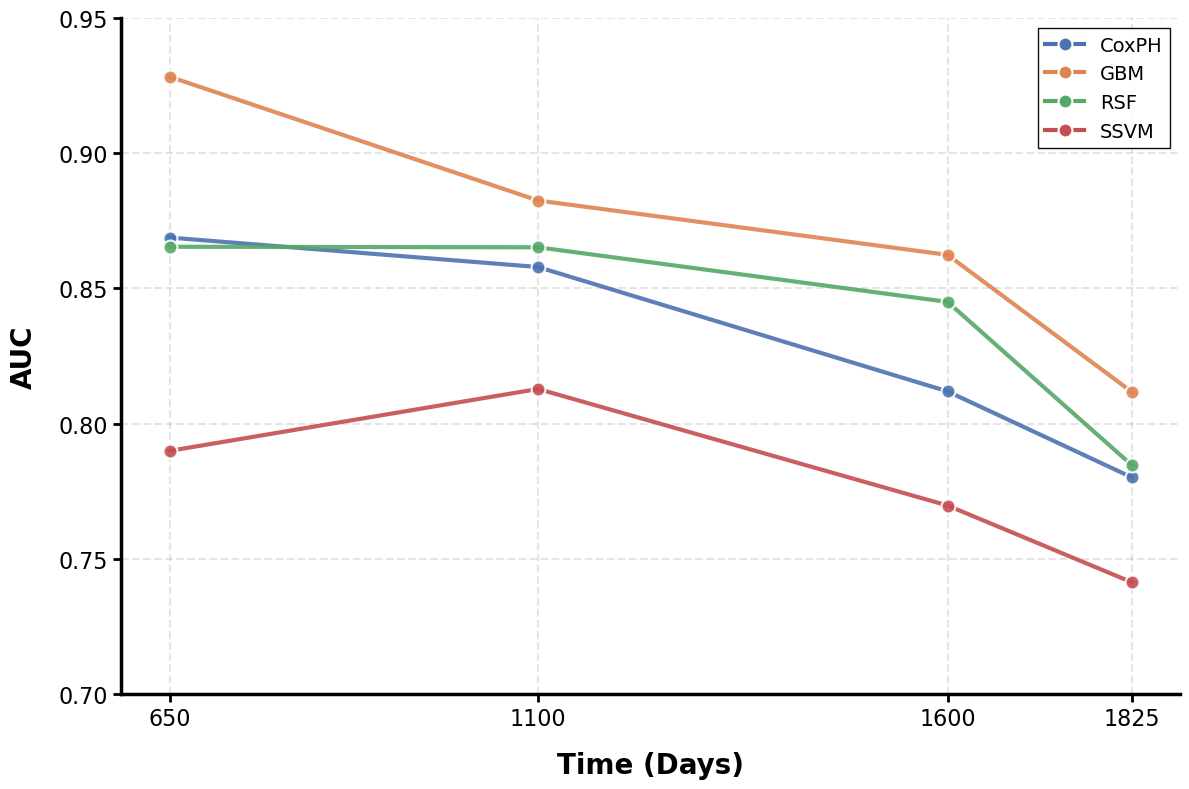

In [1]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.lines import Line2D

# data setup
time_points = [650, 1100, 1600, 1825]
models = ['CoxPH', 'GBM', 'RSF', 'SSVM']
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52'] 

means = {
    'CoxPH':  [0.8688, 0.8579, 0.8119, 0.7801],
    'GBM':  [0.9283, 0.8825, 0.8624, 0.8117],
    'RSF':  [0.8654, 0.8652, 0.8450, 0.7846],
    'SSVM': [0.7899, 0.8128, 0.7697, 0.7413]
}

# plotting
fig, ax = plt.subplots(figsize=(12, 8))
ax.set_facecolor('white')

# plot lines
for i, model in enumerate(models):
    ax.plot(time_points, means[model], 
            marker='o', 
            markersize=10, 
            linewidth=3, 
            label=model, 
            color=colors[i],
            alpha=0.9, 
            markeredgecolor='white', 
            markeredgewidth=1.5)

# axis labels
ax.set_xlabel('Time (Days)', fontsize=20, fontweight='bold', labelpad=15)
ax.set_ylabel('AUC', fontsize=20, fontweight='bold', labelpad=15)

# Ticks
ax.tick_params(axis='both', which='major', labelsize=16, width=2, length=6)
ax.set_xticks(time_points)

# Y-Axis range and grid
ax.set_ylim(0.70, 0.95)
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.05))
ax.grid(True, axis='y', alpha=0.2, linestyle='--', linewidth=1.5, color='gray')
ax.grid(True, axis='x', alpha=0.2, linestyle='--', linewidth=1.5, color='gray')

# spines - open look
# Hide the Right and Top spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Style the Left and Bottom spines (Thick and Black)
ax.spines['left'].set_visible(True)
ax.spines['left'].set_linewidth(2.5)
ax.spines['left'].set_edgecolor('black')

ax.spines['bottom'].set_visible(True)
ax.spines['bottom'].set_linewidth(2.5)
ax.spines['bottom'].set_edgecolor('black')

# Ensure grid stays behind the plot
ax.set_axisbelow(True)

# legend
legend_elements = [
    Line2D([0], [0], color=colors[i], marker='o', linestyle='-', linewidth=3, 
           markersize=10, markeredgecolor='white', markeredgewidth=1.5, label=m)
    for i, m in enumerate(models)
]

ax.legend(handles=legend_elements, 
          fontsize=14, 
          loc='upper right', 
          frameon=True, 
          framealpha=0.95, 
          edgecolor='black',
          fancybox=False)

plt.tight_layout()
plt.savefig('auc_lineplot_styled.pdf', dpi=600, bbox_inches='tight')
plt.show()

C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_25300\1325460146.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, labels=models, patch_artist=True)
C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_25300\1325460146.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, labels=models, patch_artist=True)
C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_25300\1325460146.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, labels=models, patch_artist=True)
C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_25300\13254

C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_25300\1325460146.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, labels=models, patch_artist=True)
C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_25300\1325460146.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, labels=models, patch_artist=True)
C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_25300\1325460146.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data_to_plot, labels=models, patch_artist=True)
C:\Users\Joao Goncalves\AppData\Local\Temp\ipykernel_25300\13254

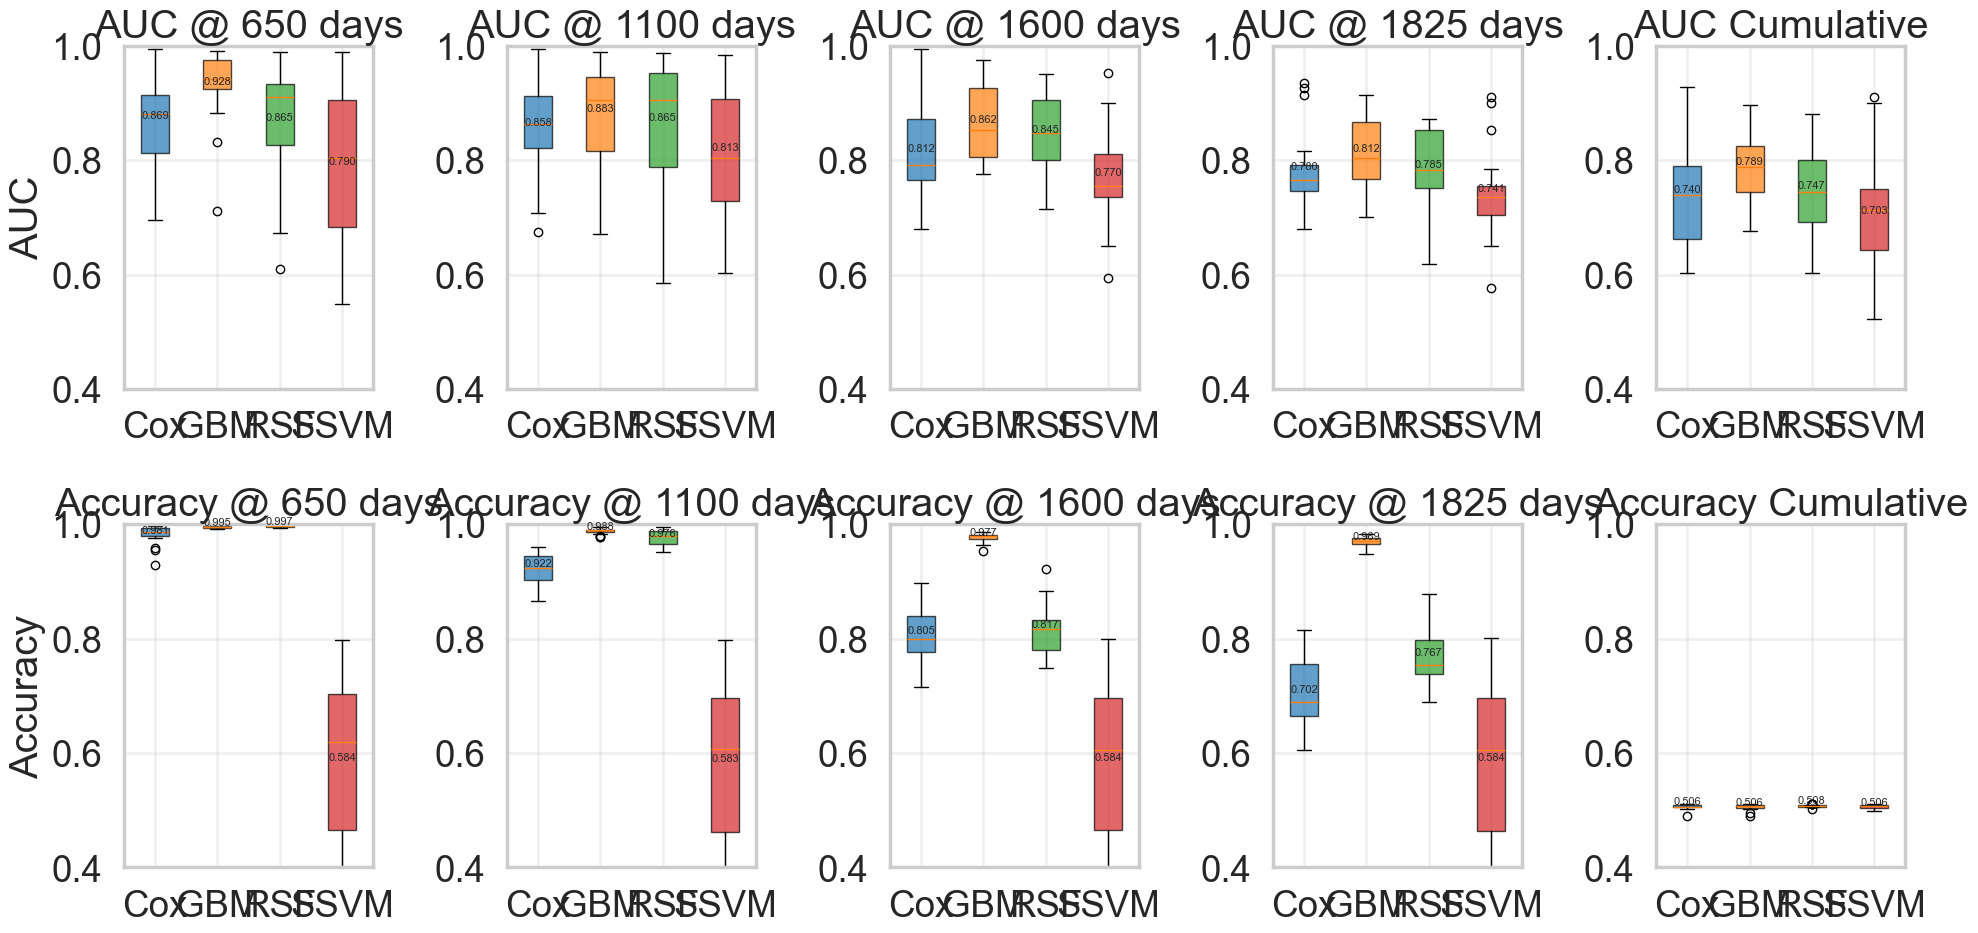

✓ Figure saved to 'figures/auc_accuracy_timepoints.png'


In [25]:
# AUC + accuracy across time points

fig, axes = plt.subplots(2, 5, figsize=(20, 10))
models = ['Cox', 'GBM', 'RSF', 'SSVM']
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
time_labels = [f'{tp}' for tp in time_points] + ['Cum']
time_keys = [f'{tp}' for tp in time_points] + ['cumulative']

# Row 1: AUC boxplots
for idx, (tp_label, tp_key) in enumerate(zip(time_labels, time_keys)):
    ax = axes[0, idx]
    data_to_plot = [all_models_results[model][f'auc_{tp_key}'] for model in models]
    
    bp = ax.boxplot(data_to_plot, labels=models, patch_artist=True)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax.set_ylabel('AUC' if idx == 0 else '')
    ax.set_title(f'AUC @ {tp_label} days' if idx < 4 else 'AUC Cumulative')
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0.4, 1.0])
    
    # Add mean values
    for i, model in enumerate(models):
        vals = all_models_results[model][f'auc_{tp_key}']
        if vals:
            mean_val = np.mean(vals)
            ax.annotate(f'{mean_val:.3f}', xy=(i+1, mean_val), ha='center', va='bottom', fontsize=8)

# Row 2: Accuracy boxplots
for idx, (tp_label, tp_key) in enumerate(zip(time_labels, time_keys)):
    ax = axes[1, idx]
    data_to_plot = [all_models_results[model][f'accuracy_{tp_key}'] for model in models]
    
    bp = ax.boxplot(data_to_plot, labels=models, patch_artist=True)
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax.set_ylabel('Accuracy' if idx == 0 else '')
    ax.set_title(f'Accuracy @ {tp_label} days' if idx < 4 else 'Accuracy Cumulative')
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0.4, 1.0])
    
    # Add mean values
    for i, model in enumerate(models):
        vals = all_models_results[model][f'accuracy_{tp_key}']
        if vals:
            mean_val = np.mean(vals)
            ax.annotate(f'{mean_val:.3f}', xy=(i+1, mean_val), ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('figures/auc_accuracy_timepoints.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Figure saved to 'figures/auc_accuracy_timepoints.png'")